# SAA readiness model

This notebook builds a **synthetic** study-habit table and fits a linear model of `mock_percent`. The rows are generated here. They are not learner records, and this notebook does not read `fixtures/saa_attempts.csv`.

The model can learn only the formula in the next section, plus the noise around it. A score is a study-focus signal. It never accepts or rejects a learner.

Run the cells from top to bottom. In Colab, pandas, sqlite3, and matplotlib are already present. The first cell installs scikit-learn only when it is missing.


In [1]:
import importlib.util
import sys

if importlib.util.find_spec("sklearn") is None:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "scikit-learn"])

import sklearn
print("scikit-learn", sklearn.__version__)
print("pandas, sqlite3, and matplotlib are left as the environment already provides them.")


scikit-learn 1.9.1
pandas, sqlite3, and matplotlib are left as the environment already provides them.


## The rule the model is allowed to learn

Eighty rows are drawn with NumPy generator seed **7**. Two of those rows are then overwritten with non-numeric values so the cleaning step has something to drop. The other 78 follow this rule and are clipped to 0–100:

`mock_percent = 35 + 0.8*study_hours + 0.05*practice_questions_answered + 0.04*flashcards_known + 2.0*mock_count + level_bonus + domain_shift + Normal(0, 3.5)`

| Piece | Value |
|---|---|
| Intercept | 35 |
| `study_hours` | 0.8 per hour |
| `practice_questions_answered` | 0.05 per question |
| `flashcards_known` | 0.04 per card |
| `mock_count` | 2.0 per mock |
| `course_level` | beginner 0, intermediate 4, advanced 8 |
| `weakest_domain` | D1 0, D2 1, D3 -1, D4 2 |
| Noise | normal, mean 0, standard deviation 3.5 |

A linear model can recover that additive rule. It cannot learn a habit, a learner, or an exam outcome that was never in the table.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 7
N = 80
rng = np.random.default_rng(SEED)

study_hours = np.round(rng.uniform(2, 40, N), 1)
practice_questions_answered = rng.integers(20, 400, N)
flashcards_known = rng.integers(0, 200, N)
mock_count = rng.integers(0, 8, N)
course_level = rng.choice(["beginner", "intermediate", "advanced"], N)
weakest_domain = rng.choice(["D1", "D2", "D3", "D4"], N)

level_bonus = {"beginner": 0.0, "intermediate": 4.0, "advanced": 8.0}
domain_shift = {"D1": 0.0, "D2": 1.0, "D3": -1.0, "D4": 2.0}
noise = rng.normal(0, 3.5, N)
mock_percent = (
    35
    + 0.8 * study_hours
    + 0.05 * practice_questions_answered
    + 0.04 * flashcards_known
    + 2.0 * mock_count
    + np.array([level_bonus[level] for level in course_level])
    + np.array([domain_shift[domain] for domain in weakest_domain])
    + noise
)
mock_percent = np.clip(np.round(mock_percent, 1), 0, 100)

frame = pd.DataFrame({
    "record_id": [f"syn-{i:03d}" for i in range(1, N + 1)],
    "study_hours": study_hours,
    "practice_questions_answered": practice_questions_answered,
    "flashcards_known": flashcards_known,
    "mock_count": mock_count,
    "course_level": course_level,
    "weakest_domain": weakest_domain,
    "mock_percent": mock_percent,
})
# Two planted bad values. They are not part of the formula the model should learn.
# Object dtype is required so pandas 3 can store the text beside the numbers.
frame["study_hours"] = frame["study_hours"].astype(object)
frame.loc[3, "study_hours"] = "n/a"
frame["mock_percent"] = frame["mock_percent"].astype(object)
frame.loc[11, "mock_percent"] = "pending"

ROOT = Path("capstone") if Path("capstone").is_dir() else Path(".")
fixture_path = ROOT / "fixtures" / "saa_readiness_synthetic.csv"
fixture_path.parent.mkdir(parents=True, exist_ok=True)
frame.to_csv(fixture_path, index=False)
print("wrote", fixture_path.as_posix())
print("rows", len(frame), "seed", SEED)
print("this file is synthetic. It is not fixtures/saa_attempts.csv.")
frame.head()


wrote capstone/fixtures/saa_readiness_synthetic.csv
rows 80 seed 7
this file is synthetic. It is not fixtures/saa_attempts.csv.


,record_id,study_hours,practice_questions_answered,flashcards_known,mock_count,course_level,weakest_domain,mock_percent
0,syn-001,25.8,233,194,3,intermediate,D4,88.4
1,syn-002,36.1,93,2,1,advanced,D2,70.5
2,syn-003,31.5,305,173,2,intermediate,D1,91.2
3,syn-004,n/a,372,125,7,intermediate,D2,85.9
4,syn-005,13.4,113,97,6,beginner,D4,69.5


In [3]:
raw = pd.read_csv(fixture_path)
print("shape", raw.shape)
print(raw.head())
raw.info()
print(raw.describe(include="all"))

numeric_columns = [
    "study_hours",
    "practice_questions_answered",
    "flashcards_known",
    "mock_count",
    "mock_percent",
]
cleaned = raw.copy()
for column in numeric_columns:
    cleaned[column] = pd.to_numeric(cleaned[column], errors="coerce")

dropped = cleaned[cleaned[numeric_columns].isna().any(axis=1)]
print("dropped rows", len(dropped))
print(dropped.to_string(index=False))
model_frame = cleaned.drop(index=dropped.index).reset_index(drop=True)
print("rows kept", len(model_frame))


shape (80, 8)
  record_id  study_hours  practice_questions_answered  flashcards_known  \
0   syn-001         25.8                          233               194   
1   syn-002         36.1                           93                 2   
2   syn-003         31.5                          305               173   
3   syn-004          NaN                          372               125   
4   syn-005         13.4                          113                97   

   mock_count  course_level weakest_domain mock_percent  
0           3  intermediate             D4         88.4  
1           1      advanced             D2         70.5  
2           2  intermediate             D1         91.2  
3           7  intermediate             D2         85.9  
4           6      beginner             D4         69.5  
<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       ----

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

FEATURES = [
    "study_hours",
    "practice_questions_answered",
    "flashcards_known",
    "mock_count",
    "course_level",
    "weakest_domain",
]
TARGET = "mock_percent"
numeric = ["study_hours", "practice_questions_answered", "flashcards_known", "mock_count"]
categorical = ["course_level", "weakest_domain"]

X = model_frame[FEATURES]
y = model_frame[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=20, random_state=SEED)

preprocess = ColumnTransformer([
    ("scale", StandardScaler(), numeric),
    ("labels", OneHotEncoder(handle_unknown="ignore"), categorical),
])
print("n_train", len(X_train), "n_test", len(X_test), "seed", SEED)
print("feature columns", list(X_train.columns))


n_train 58 n_test 20 seed 7
feature columns ['study_hours', 'practice_questions_answered', 'flashcards_known', 'mock_count', 'course_level', 'weakest_domain']


In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dummy = Pipeline([
    ("prep", preprocess),
    ("model", DummyRegressor(strategy="mean")),
])
linear = Pipeline([
    ("prep", preprocess),
    ("model", LinearRegression()),
])
# One tree, fixed before looking at the test score. It is not tuned.
tree = Pipeline([
    ("prep", preprocess),
    ("model", DecisionTreeRegressor(max_depth=3, random_state=SEED)),
])

dummy.fit(X_train, y_train)
linear.fit(X_train, y_train)
tree.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)
linear_pred = linear.predict(X_test)
tree_pred = tree.predict(X_test)

def metric_row(name, predicted):
    return {
        "model": name,
        "n_train": len(X_train),
        "n_test": len(X_test),
        "seed": SEED,
        "MAE": mean_absolute_error(y_test, predicted),
        "RMSE": mean_squared_error(y_test, predicted) ** 0.5,
        "R2": r2_score(y_test, predicted),
    }

metrics = pd.DataFrame([
    metric_row("dummy_mean", dummy_pred),
    metric_row("linear_regression", linear_pred),
    metric_row("tree_depth_3", tree_pred),
])
metrics


,model,n_train,n_test,seed,MAE,RMSE,R2
0,dummy_mean,58,20,7,12.631207,14.936468,-0.047033
1,linear_regression,58,20,7,4.072198,4.705085,0.896104
2,tree_depth_3,58,20,7,6.938952,8.542540,0.657517


wrote capstone/outputs/predicted_vs_actual.png
wrote capstone/outputs/residuals.png


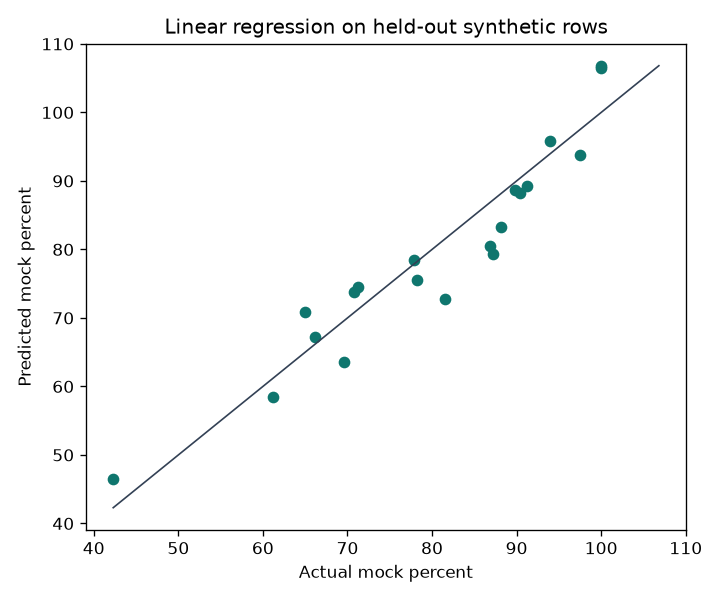

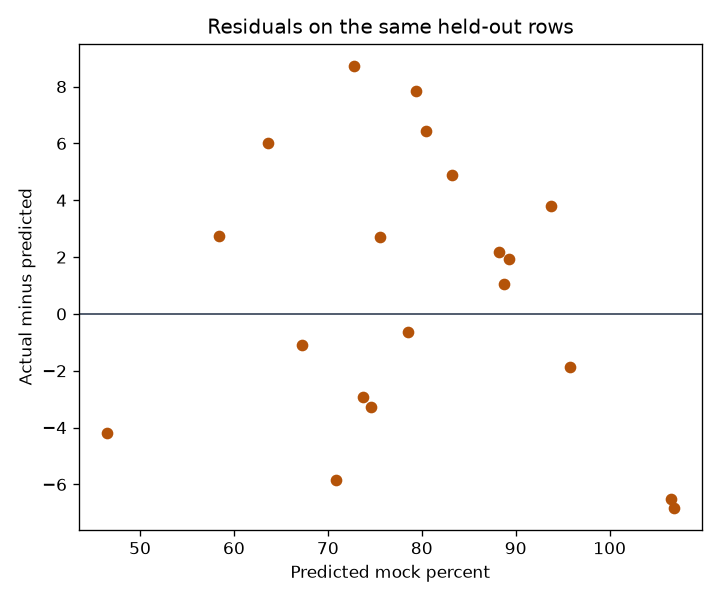

In [6]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

output_dir = ROOT / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, linear_pred, color="#0f766e")
low = min(y_test.min(), linear_pred.min())
high = max(y_test.max(), linear_pred.max())
ax.plot([low, high], [low, high], color="#334155", linewidth=1)
ax.set_xlabel("Actual mock percent")
ax.set_ylabel("Predicted mock percent")
ax.set_title("Linear regression on held-out synthetic rows")
fig.tight_layout()
predicted_path = output_dir / "predicted_vs_actual.png"
fig.savefig(predicted_path, dpi=120)
plt.close(fig)

residuals = y_test.to_numpy() - linear_pred
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(linear_pred, residuals, color="#b45309")
ax.axhline(0, color="#334155", linewidth=1)
ax.set_xlabel("Predicted mock percent")
ax.set_ylabel("Actual minus predicted")
ax.set_title("Residuals on the same held-out rows")
fig.tight_layout()
residual_path = output_dir / "residuals.png"
fig.savefig(residual_path, dpi=120)
plt.close(fig)
print("wrote", predicted_path.as_posix())
print("wrote", residual_path.as_posix())

from IPython.display import Image, display
display(Image(filename=str(predicted_path)))
display(Image(filename=str(residual_path)))


In [7]:
linear_mae = float(metrics.loc[metrics.model == "linear_regression", "MAE"].iloc[0])
dummy_mae = float(metrics.loc[metrics.model == "dummy_mean", "MAE"].iloc[0])
linear_rmse = float(metrics.loc[metrics.model == "linear_regression", "RMSE"].iloc[0])
dummy_rmse = float(metrics.loc[metrics.model == "dummy_mean", "RMSE"].iloc[0])
beat = linear_mae < dummy_mae
if beat:
    takeaway = (
        f"On the same {len(y_test)} held-out synthetic rows, linear regression "
        f"beat the dummy on MAE ({linear_mae:.2f} vs {dummy_mae:.2f}). "
        f"RMSE was {linear_rmse:.2f} against the dummy's {dummy_rmse:.2f}. "
        "That is expected: the table was built from an additive formula plus modest noise, "
        "and a line can recover that formula. The fit was not tuned after seeing this score. "
        "The number is a study-focus signal for these made-up rows. It does not accept or reject a learner, "
        "and it says nothing about a real exam."
    )
else:
    takeaway = (
        f"On the same {len(y_test)} held-out synthetic rows, linear regression did not beat "
        f"the dummy on MAE ({linear_mae:.2f} vs {dummy_mae:.2f}). "
        f"RMSE was {linear_rmse:.2f} against the dummy's {dummy_rmse:.2f}. "
        "The fit was left as specified. Nothing was tuned to try to win. "
        "A score from this table is still only a study-focus signal. It does not accept or reject a learner."
    )

metric_lines = [
    "| Model | n_train | n_test | seed | MAE | RMSE | R2 |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for row in metrics.itertuples(index=False):
    metric_lines.append(
        f"| {row.model} | {row.n_train} | {row.n_test} | {row.seed} | {row.MAE:.3f} | {row.RMSE:.3f} | {row.R2:.3f} |"
    )

report = f"""# SAA readiness evaluation

## 1. Run metadata

- Seed: {SEED} for the row generator, the train/test split, and the optional tree.
- Generated rows: {N}. Dropped after `to_numeric(..., errors="coerce")`: {len(dropped)}. Kept: {len(model_frame)}.
- Split: {len(X_train)} train, {len(X_test)} test. `test_size` was the integer 20.
- Target: `mock_percent`. Features: {", ".join(FEATURES)}.
- Formula: `35 + 0.8*study_hours + 0.05*practice_questions_answered + 0.04*flashcards_known + 2.0*mock_count + level bonus (0/4/8) + domain shift (0/1/-1/2) + Normal(0, 3.5)`, clipped to 0–100.
- Data: synthetic rows written by this notebook. No learner records and no `saa_attempts.csv`.
- scikit-learn {sklearn.__version__}. pandas, sqlite3, and matplotlib were already in the environment.

## 2. Metrics vs dummy

The dummy predicts the training-set mean for every held-out row. The tree is one extra model with `max_depth=3` and the same seed. It was not tuned.

{chr(10).join(metric_lines)}

## 3. Takeaway

{takeaway}

## 4. Limits and leakage checklist

- `mock_percent` is the target. It is not a feature.
- Scaling and one-hot encoding are inside a pipeline fit on the training rows only.
- The split is made before any model is fit.
- The only signal is the documented formula plus noise. The model cannot know anything else.
- The two non-numeric rows are dropped and printed. They are not imputed into the fit.
- No hyperparameter search was run after seeing the held-out score.
- These scores suggest where synthetic study effort sits. They never accept or reject a learner.
"""
report_path = ROOT / "ml_evaluation_report.md"
report_path.write_text(report)
print(report)
print("wrote", report_path.as_posix())
print("linear regression beat the dummy." if beat else "linear regression did not beat the dummy.")


# SAA readiness evaluation

## 1. Run metadata

- Seed: 7 for the row generator, the train/test split, and the optional tree.
- Generated rows: 80. Dropped after `to_numeric(..., errors="coerce")`: 2. Kept: 78.
- Split: 58 train, 20 test. `test_size` was the integer 20.
- Target: `mock_percent`. Features: study_hours, practice_questions_answered, flashcards_known, mock_count, course_level, weakest_domain.
- Formula: `35 + 0.8*study_hours + 0.05*practice_questions_answered + 0.04*flashcards_known + 2.0*mock_count + level bonus (0/4/8) + domain shift (0/1/-1/2) + Normal(0, 3.5)`, clipped to 0–100.
- Data: synthetic rows written by this notebook. No learner records and no `saa_attempts.csv`.
- scikit-learn 1.9.1. pandas, sqlite3, and matplotlib were already in the environment.

## 2. Metrics vs dummy

The dummy predicts the training-set mean for every held-out row. The tree is one extra model with `max_depth=3` and the same seed. It was not tuned.

| Model | n_train | n_test | seed | MAE 

This is the report written by the cell above on the saved run.

# SAA readiness evaluation

## 1. Run metadata

- Seed: 7 for the row generator, the train/test split, and the optional tree.
- Generated rows: 80. Dropped after `to_numeric(..., errors="coerce")`: 2. Kept: 78.
- Split: 58 train, 20 test. `test_size` was the integer 20.
- Target: `mock_percent`. Features: study_hours, practice_questions_answered, flashcards_known, mock_count, course_level, weakest_domain.
- Formula: `35 + 0.8*study_hours + 0.05*practice_questions_answered + 0.04*flashcards_known + 2.0*mock_count + level bonus (0/4/8) + domain shift (0/1/-1/2) + Normal(0, 3.5)`, clipped to 0–100.
- Data: synthetic rows written by this notebook. No learner records and no `saa_attempts.csv`.
- scikit-learn 1.9.1. pandas, sqlite3, and matplotlib were already in the environment.

## 2. Metrics vs dummy

The dummy predicts the training-set mean for every held-out row. The tree is one extra model with `max_depth=3` and the same seed. It was not tuned.

| Model | n_train | n_test | seed | MAE | RMSE | R2 |
|---|---:|---:|---:|---:|---:|---:|
| dummy_mean | 58 | 20 | 7 | 12.631 | 14.936 | -0.047 |
| linear_regression | 58 | 20 | 7 | 4.072 | 4.705 | 0.896 |
| tree_depth_3 | 58 | 20 | 7 | 6.939 | 8.543 | 0.658 |

## 3. Takeaway

On the same 20 held-out synthetic rows, linear regression beat the dummy on MAE (4.07 vs 12.63). RMSE was 4.71 against the dummy's 14.94. That is expected: the table was built from an additive formula plus modest noise, and a line can recover that formula. The fit was not tuned after seeing this score. The number is a study-focus signal for these made-up rows. It does not accept or reject a learner, and it says nothing about a real exam.

## 4. Limits and leakage checklist

- `mock_percent` is the target. It is not a feature.
- Scaling and one-hot encoding are inside a pipeline fit on the training rows only.
- The split is made before any model is fit.
- The only signal is the documented formula plus noise. The model cannot know anything else.
- The two non-numeric rows are dropped and printed. They are not imputed into the fit.
- No hyperparameter search was run after seeing the held-out score.
- These scores suggest where synthetic study effort sits. They never accept or reject a learner.


## SQL next to pandas

The three checks use an in-memory SQLite database loaded from the cleaned synthetic table. Each query is printed beside the pandas equivalent. Nothing is written to a database file.


In [8]:
import sqlite3

conn = sqlite3.connect(":memory:")
model_frame.to_sql("readiness", conn, index=False)

average_by_domain = """
SELECT weakest_domain, AVG(mock_percent) AS avg_mock_percent, COUNT(*) AS n
FROM readiness
GROUP BY weakest_domain
ORDER BY weakest_domain
"""
under_80 = """
SELECT record_id, weakest_domain, mock_count, mock_percent
FROM readiness
WHERE mock_percent < 80 AND mock_count >= 2
ORDER BY mock_percent
"""
buckets = """
SELECT
  CASE
    WHEN study_hours < 10 THEN 'under 10'
    WHEN study_hours < 25 THEN '10 to 24'
    ELSE '25 or more'
  END AS study_bucket,
  CASE
    WHEN practice_questions_answered < 100 THEN 'under 100'
    WHEN practice_questions_answered < 250 THEN '100 to 249'
    ELSE '250 or more'
  END AS practice_bucket,
  AVG(mock_percent) AS avg_mock_percent,
  COUNT(*) AS n
FROM readiness
GROUP BY study_bucket, practice_bucket
ORDER BY study_bucket, practice_bucket
"""

print("SQL average mock_percent by weakest_domain")
print(pd.read_sql_query(average_by_domain, conn).to_string(index=False))
print("pandas")
print(model_frame.groupby("weakest_domain", as_index=False)["mock_percent"].agg(avg_mock_percent="mean", n="count").sort_values("weakest_domain").to_string(index=False))

print("SQL rows under 80 with at least 2 mocks")
print(pd.read_sql_query(under_80, conn).to_string(index=False))
print("pandas")
under = model_frame[(model_frame.mock_percent < 80) & (model_frame.mock_count >= 2)][
    ["record_id", "weakest_domain", "mock_count", "mock_percent"]
].sort_values("mock_percent")
print(under.to_string(index=False))

print("SQL study-hour buckets vs practice-question buckets")
print(pd.read_sql_query(buckets, conn).to_string(index=False))
print("pandas")
banded = model_frame.assign(
    study_bucket=pd.cut(model_frame.study_hours, [-0.1, 10, 25, 100], labels=["under 10", "10 to 24", "25 or more"], right=False),
    practice_bucket=pd.cut(model_frame.practice_questions_answered, [-1, 100, 250, 1000], labels=["under 100", "100 to 249", "250 or more"], right=False),
)
print(banded.groupby(["study_bucket", "practice_bucket"], observed=False)["mock_percent"].agg(avg_mock_percent="mean", n="count").reset_index().to_string(index=False))
conn.close()


SQL average mock_percent by weakest_domain
weakest_domain  avg_mock_percent  n
            D1         81.180000 20
            D2         75.235294 17
            D3         72.460000 20
            D4         82.823810 21
pandas
weakest_domain  avg_mock_percent  n
            D1         81.180000 20
            D2         75.235294 17
            D3         72.460000 20
            D4         82.823810 21
SQL rows under 80 with at least 2 mocks
record_id weakest_domain  mock_count  mock_percent
  syn-038             D3           5          50.6
  syn-007             D4           4          55.3
  syn-055             D3           3          58.8
  syn-022             D2           3          60.9
  syn-075             D3           3          64.7
  syn-015             D1           3          65.0
  syn-034             D1           6          67.8
  syn-024             D3           5          69.3
  syn-005             D4           6          69.5
  syn-025             D2           3    

In [9]:
assert len(X_train) == 58, len(X_train)
assert len(X_test) == 20, len(X_test)
assert TARGET not in list(X_train.columns)
assert TARGET not in FEATURES
assert predicted_path.is_file()
assert residual_path.is_file()
print("split", len(X_train), len(X_test))
print("mock_percent is not a feature")
print("plots", predicted_path.name, residual_path.name)
print("linear regression beat the dummy." if beat else "linear regression did not beat the dummy.")


split 58 20
mock_percent is not a feature
plots predicted_vs_actual.png residuals.png
linear regression beat the dummy.
